# Overview

In this notebook, I explore the Trending Youtube Video Statistics Dataset from Kaggle (https://www.kaggle.com/datasets/datasnaek/youtube-new/data). I have been learning to use Polars Dataframes this week, and explore this dataset as a practice in this notebook. I am quite new to Datascience, so this is gonna be very...let's say raw. :-)

# Setting Up
We start with imports...

In [44]:
import kagglehub
import shutil
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

In [45]:
pl.Config.set_tbl_rows(250) # i like looking at long tables
pl.Config.set_fmt_str_lengths(None)
pl.Config.set_tbl_width_chars(50)
pl.Config.set_thousands_separator(True)

plt.style.use('fivethirtyeight')
sns.set_context('notebook')

...and loading the dataset through kagglehub. I start exploring the dataset for the US first (the dataset also contains csv-files for other markets as well as accompanying json files that explain the category codes in the csv file. Let's ignore those for now). I intend to keep `us_original` as a dataframe containing the raw data, while we will process the data in the dataframe `us`:

In [46]:

path = kagglehub.dataset_download("datasnaek/youtube-new")
shutil.copytree(path, "./data", dirs_exist_ok=True)

us_original = us = pl.read_csv("./data/USvideos.csv")


Let's take a look inside (I use pl.glimpse() instead of a simple head() so some of the very long strings in the dataframe will be readable in full):

In [47]:
us.glimpse()

Rows: 40949
Columns: 16
$ video_id                <str> '2kyS6SvSYSE', '1ZAPwfrtAFY', '5qpjK5DgCt4', 'puqaWrEC7tY', 'd380meD0W0M', 'gHZ1Qz0KiKM', '39idVpFF7NQ', 'nc99ccSXST0', 'jr9QtXwC9vc', 'TUmyygCMMGA'
$ trending_date           <str> '17.14.11', '17.14.11', '17.14.11', '17.14.11', '17.14.11', '17.14.11', '17.14.11', '17.14.11', '17.14.11', '17.14.11'
$ title                   <str> 'WE WANT TO TALK ABOUT OUR MARRIAGE', 'The Trump Presidency: Last Week Tonight with John Oliver (HBO)', 'Racist Superman | Rudy Mancuso, King Bach & Lele Pons', 'Nickelback Lyrics: Real or Fake?', 'I Dare You: GOING BALD!?', '2 Weeks with iPhone X', 'Roy Moore & Jeff Sessions Cold Open - SNL', '5 Ice Cream Gadgets put to the Test', 'The Greatest Showman | Official Trailer 2 [HD] | 20th Century FOX', 'Why the rise of the robots won’t mean the end of work'
$ channel_title           <str> 'CaseyNeistat', 'LastWeekTonight', 'Rudy Mancuso', 'Good Mythical Morning', 'nigahiga', 'iJustine', 'Saturday Night Live'

# Looking at Dates
## Formatting the trending_date column
The `trending_date` column contains dates for each entry, but is currently encoded as a string. Let's try to turn that into a proper date format. First we need to figure out how the dates are currently encoded. The first entry is "17.14.11" which unfortunately doesn't narrow down our options too much. However, looking at the `trending_date` together with the `publish_time` column gives us the necessary info:

In [48]:
us["trending_date", "publish_time"].head(3)

trending_date,publish_time
str,str
"""17.14.11""","""2017-11-13T17:13:01.000Z"""
"""17.14.11""","""2017-11-13T07:30:00.000Z"""
"""17.14.11""","""2017-11-12T19:05:24.000Z"""


If we make the reasonable assumption that most trending videos were published in the days before, we can see that the first number (17) shows the year (2017), followed by the day (14) and the month (11). So let's reformat our `trending_date` column:

In [49]:
us = us_original.with_columns(trending_date=pl.col("trending_date").str.to_date("%y.%d.%m"))
us.head()

video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
str,date,str,str,i64,str,str,i64,i64,i64,i64,str,bool,bool,bool,str
"""2kyS6SvSYSE""",2017-11-14,"""WE WANT TO TALK ABOUT OUR MARR…","""CaseyNeistat""",22,"""2017-11-13T17:13:01.000Z""","""SHANtell martin""","748,374","57,527","2,966","15,954","""https://i.ytimg.com/vi/2kyS6Sv…",false,false,false,"""SHANTELL'S CHANNEL - https://w…"
"""1ZAPwfrtAFY""",2017-11-14,"""The Trump Presidency: Last Wee…","""LastWeekTonight""",24,"""2017-11-13T07:30:00.000Z""","""last week tonight trump presid…","2,418,783","97,185","6,146","12,703","""https://i.ytimg.com/vi/1ZAPwfr…",false,false,false,"""One year after the presidentia…"
"""5qpjK5DgCt4""",2017-11-14,"""Racist Superman | Rudy Mancuso…","""Rudy Mancuso""",23,"""2017-11-12T19:05:24.000Z""","""racist superman|rudy|mancuso|k…","3,191,434","146,033","5,339","8,181","""https://i.ytimg.com/vi/5qpjK5D…",false,false,false,"""WATCH MY PREVIOUS VIDEO ▶ \n\n…"
"""puqaWrEC7tY""",2017-11-14,"""Nickelback Lyrics: Real or Fak…","""Good Mythical Morning""",24,"""2017-11-13T11:00:04.000Z""","""rhett and link|gmm|good mythic…","343,168","10,172",666,"2,146","""https://i.ytimg.com/vi/puqaWrE…",false,false,false,"""Today we find out if Link is a…"
"""d380meD0W0M""",2017-11-14,"""I Dare You: GOING BALD!?""","""nigahiga""",24,"""2017-11-12T18:01:41.000Z""","""ryan|higa|higatv|nigahiga|i da…","2,095,731","132,235","1,989","17,518","""https://i.ytimg.com/vi/d380meD…",false,false,false,"""I know it's been a while since…"


## When is the data from
Armed with our properly formatted dates, we can tackle our first question: Over what time period was our data collected? The `.describe()` method shows that the answer is from 14 Nov 2017 (the min value) to 14 June 2018 (the max value). This roughly tracks with the number of unique dates in the data (205), since we have around 7 months of data (~210 days).

In [50]:
us.get_column("trending_date").describe()

statistic,value
str,str
"""count""","""40949"""
"""null_count""","""0"""
"""mean""","""2018-02-27 06:22:42.494810"""
"""min""","""2017-11-14"""
"""25%""","""2018-01-04"""
"""50%""","""2018-02-26"""
"""75%""","""2018-04-24"""
"""max""","""2018-06-14"""


In [51]:
us.get_column("trending_date").n_unique()

205

Let's try to be a bit more precise and see if we have data for every day during the period of our dataset:

In [52]:
by_date = us.group_by('trending_date').len().sort("trending_date")
date_range = pl.date_range(start=by_date['trending_date'][0], end=by_date['trending_date'][-1], interval="1d", eager=True)
date_range.len()


213

Uh oh! Our `group_by`-dates object has 205 entries, but the date_range has 213! So some days are missing. Let's try to get the missing values:

In [53]:
date_range.to_frame('date_range').join(by_date, left_on="date_range", right_on="trending_date", how='anti')

date_range
date
2018-01-10
2018-01-11
2018-04-08
2018-04-09
2018-04-10
2018-04-11
2018-04-12
2018-04-13


So two days in January and 6 in April are missing. Not too bad.

## Some timeseries data analysis
Let's see if we can figure out some trends from our time-series data. Above we created a group_by-object based on the `trending_date`, as we can see we generally have 200 entries per day exactly, representing (I assume) 200 unique videos per day:

In [54]:
by_date.describe()

statistic,trending_date,len
str,str,f64
"""count""","""205""",205.0
"""null_count""","""0""",0.0
"""mean""","""2018-02-27 06:12:17.560975""",199.75122
"""std""",null,0.687109
"""min""","""2017-11-14""",196.0
"""25%""","""2018-01-04""",200.0
"""50%""","""2018-02-26""",200.0
"""75%""","""2018-04-24""",200.0
"""max""","""2018-06-14""",200.0


Let's create some aggregate data per day, namely how many views, comments, likes and dislikes our videos generated. I am also including normalized versions of this data, to make comparison easier later on:

In [55]:
by_date = us.group_by('trending_date').agg(
    pl.col('views'          ).sum().alias('total_views'), 
    pl.col('comment_count'  ).sum().alias('total_comments'),
    pl.col('likes'          ).sum().alias('total_likes'),
    pl.col('dislikes'       ).sum().alias('total_dislikes'),
    ).sort('trending_date')

by_date = by_date.with_columns(
    norm_views = pl.col('total_views') / pl.col('total_views').max(),
    norm_comments = pl.col('total_comments') / pl.col('total_comments').max(),
    norm_likes = pl.col('total_likes') / pl.col('total_likes').max(),
    norm_dislikes = pl.col('total_dislikes') / pl.col('total_dislikes').max(),
)
by_date.head()

trending_date,total_views,total_comments,total_likes,total_dislikes,norm_views,norm_comments,norm_likes,norm_dislikes
date,i64,i64,i64,i64,f64,f64,f64,f64
2017-11-14,"185,435,246","691,402","7,637,635","270,876",0.152818,0.16334,0.217793,0.127732
2017-11-15,"212,445,216","709,009","7,601,148","313,577",0.175077,0.1675,0.216753,0.147868
2017-11-16,"227,365,391","735,962","7,886,807","338,755",0.187373,0.173867,0.224898,0.159741
2017-11-17,"193,541,711","814,596","7,143,580","341,176",0.159499,0.192444,0.203705,0.160882
2017-11-18,"196,846,875","901,370","8,393,717","322,349",0.162223,0.212944,0.239353,0.152004


I want to plot how our engagement metrics evolved over time. The following code shows them separated into views/comments and likes/dislikes respectively. I start with seaborn line plots and then customise the ticks (the markings on the x and y axis) using matplotlib.

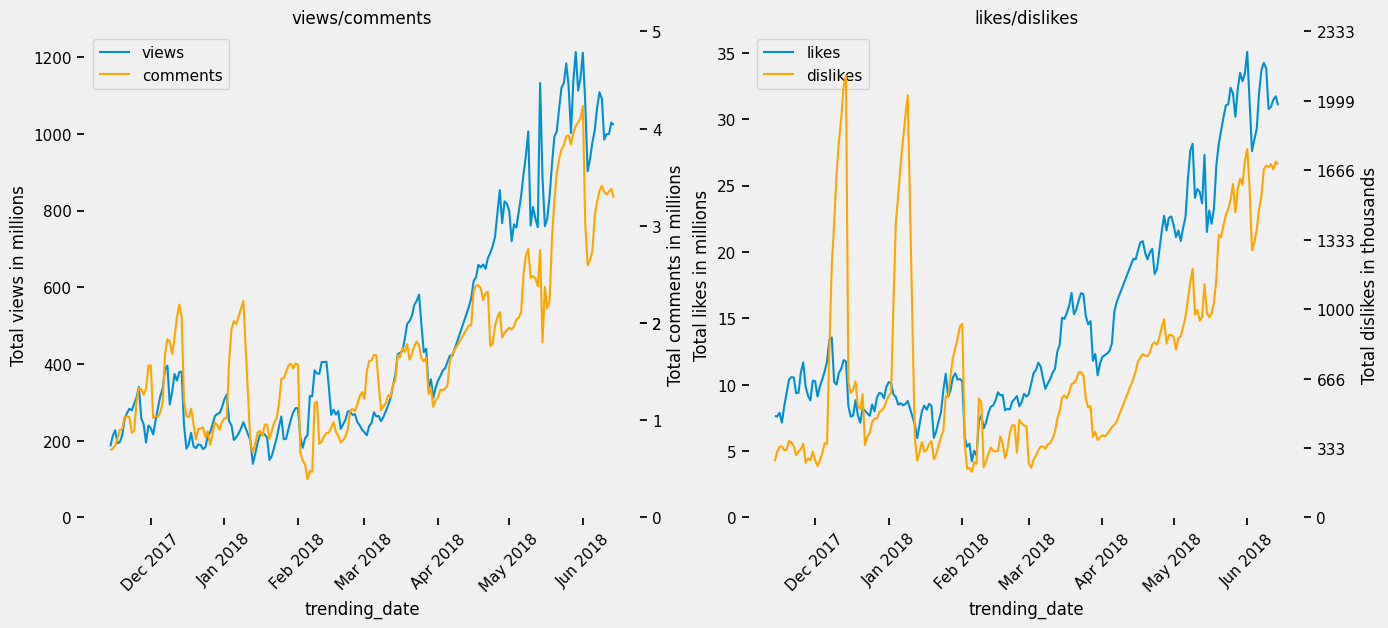

In [56]:
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(14, 6))

sns.lineplot(data=by_date, x='trending_date', y='total_views', label='views', legend='full', ax=ax1)
ax1.grid(False)
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))  # e.g., "Jan 2024"
ax1.tick_params(axis='x', rotation=45)

ax1.set_ylabel('Total views in millions')
max_total_views = int(by_date['total_views'].max() * 1.1)
ax1.set_yticks(range(0, max_total_views, int(2e8)))
yticks = ax1.get_yticks()
ax1.set_yticklabels([f"{int(y / 1e6)}" for y in yticks])

ax1.set_title('views/comments')

ax2 = ax1.twinx()
sns.lineplot(data=by_date, x='trending_date', y='total_comments', ax=ax2, color='orange', label='comments')
ax2.grid(False)
max_comments = int(by_date['total_comments'].max() * 1.1)
ax2.set_yticks(np.linspace(0, max_comments, len(ax1.get_yticks())).round(decimals=-6).astype(int))
ax2.set_yticklabels([f"{int(y / 1e6)}" for y in ax2.get_yticks()])
ax2.set_ylabel('Total comments in millions')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)
ax2.get_legend().remove()

#########

sns.lineplot(data=by_date, x='trending_date', y='total_likes', label='likes', legend='full', ax=ax3)
ax3.grid(False)
ax3.set_title('likes/dislikes')

ax3.xaxis.set_major_locator(mdates.MonthLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))  # e.g., "Jan 2024"

ax3.set_ylabel('Total likes in millions')
max_total_likes = int(by_date['total_likes'].max() * 1.1)
ax3.set_yticks(range(0, max_total_likes, int(5e6)))
yticks = ax3.get_yticks()
ax3.set_yticklabels([f"{int(y / 1e6)}" for y in yticks])
ax3.tick_params(axis='x', rotation=45)

ax4 = ax3.twinx()
sns.lineplot(data=by_date, x='trending_date', y='total_dislikes', ax=ax4, color='orange', label='dislikes')
ax4.grid(False)
max_dislikes = int(by_date['total_dislikes'].max() * 1.1)
ax4.set_yticks(np.linspace(0, max_dislikes, len(ax3.get_yticks())).round(decimals=-3).astype(int))
ax4.set_yticklabels([f"{int(y / 1e3)}" for y in ax4.get_yticks()])
ax4.set_ylabel('Total dislikes in thousands')

lines1, labels1 = ax3.get_legend_handles_labels()
lines2, labels2 = ax4.get_legend_handles_labels()
ax3.legend(lines1 + lines2, labels1 + labels2)
ax4.get_legend().remove()


We can see a clear upwards trend in all metrics. However, the dislike-category shows huge spikes that I want to look into in more detail later. 

Let's overlay all four metrics on one diagram so we can compare trends better. Here I use the normalized columns we created earlier to make comparison easier. Technically, we convert the column into row data through the `unpivot` method before plotting them simply with seaborn. This would have been easier with pandas.

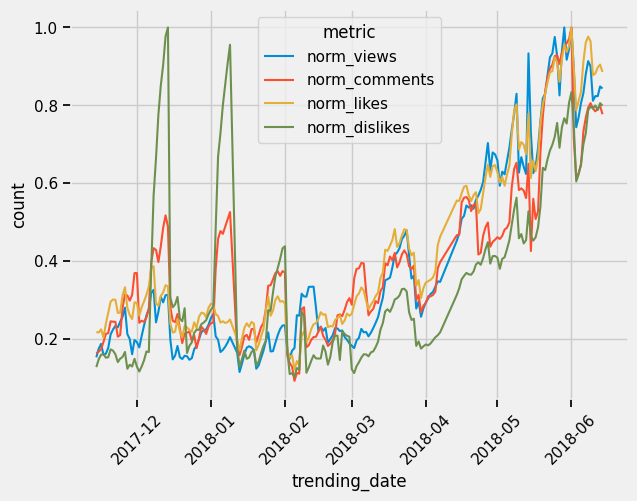

In [57]:
long_norm = by_date.unpivot(index='trending_date', on=['norm_views', 'norm_comments', 'norm_likes', 'norm_dislikes'], variable_name='metric', value_name='count')

sns.lineplot(data=long_norm, x='trending_date', y='count', hue='metric')
plt.xticks(rotation=45)
plt.show()

Again we see the big spikes on the dislikes in December 2017 and January 2018. In this diagram, we can see that they are accompanied with spikes in the comments count as well. This correlation would have been harder to spot in the separate diagrams above. Conversely, you can see that the viewership and likes counts seem to move together a little bit for some of the spikes in May and June 2018. We can calculate the correlation coefficents later for all individual data points

# Categories

Let's look at some of the other columns on offer. One category - is called category_id. The datatype is integers, but it is categorical data. The json explains it. For instance, "id 23" refers to "Comedy" and "id 27" to "Education". Let's decode our category codes and count how popular each category is.

Decoding:

In [58]:
import json

with open("./data/US_category_id.json") as f:
    items = json.load(f)['items']
    categories = {int(item['id']) : item['snippet']['title'] for item in items}

categories

{1: 'Film & Animation',
 2: 'Autos & Vehicles',
 10: 'Music',
 15: 'Pets & Animals',
 17: 'Sports',
 18: 'Short Movies',
 19: 'Travel & Events',
 20: 'Gaming',
 21: 'Videoblogging',
 22: 'People & Blogs',
 23: 'Comedy',
 24: 'Entertainment',
 25: 'News & Politics',
 26: 'Howto & Style',
 27: 'Education',
 28: 'Science & Technology',
 29: 'Nonprofits & Activism',
 30: 'Movies',
 31: 'Anime/Animation',
 32: 'Action/Adventure',
 33: 'Classics',
 34: 'Comedy',
 35: 'Documentary',
 36: 'Drama',
 37: 'Family',
 38: 'Foreign',
 39: 'Horror',
 40: 'Sci-Fi/Fantasy',
 41: 'Thriller',
 42: 'Shorts',
 43: 'Shows',
 44: 'Trailers'}

In [59]:
us = us.with_columns(pl.col('category_id').replace_strict(categories).alias('category_name'))
us.select('category_id', 'category_name').head(10)

category_id,category_name
i64,str
22,"""People & Blogs"""
24,"""Entertainment"""
23,"""Comedy"""
24,"""Entertainment"""
24,"""Entertainment"""
28,"""Science & Technology"""
24,"""Entertainment"""
28,"""Science & Technology"""
1,"""Film & Animation"""


In [60]:
us.filter(~pl.col('category_id').is_in(categories)) # all rows have valid category keys

video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name
str,date,str,str,i64,str,str,i64,i64,i64,i64,str,bool,bool,bool,str,str


Let's look at the numbers first. Note that the .JSON contained 32 categories, but only 16 actually show up in the dataset.

In [61]:
by_cat = us.group_by('category_name').len().sort('len', descending=True).with_columns((pl.col('len') / pl.sum('len')).alias('percentage'))
by_cat

category_name,len,percentage
str,u32,f64
"""Entertainment""","9,964",0.243327
"""Music""","6,472",0.15805
"""Howto & Style""","4,146",0.101248
"""Comedy""","3,457",0.084422
"""People & Blogs""","3,210",0.07839
"""News & Politics""","2,487",0.060734
"""Science & Technology""","2,401",0.058634
"""Film & Animation""","2,345",0.057266
"""Sports""","2,174",0.05309


/var/folders/25/s9pgc_hn4d37f3vcvhdwm6nr0000gn/T/ipykernel_91819/2993098429.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels([f"{int(x * 100)}%" for x in ax2.get_xticks()])


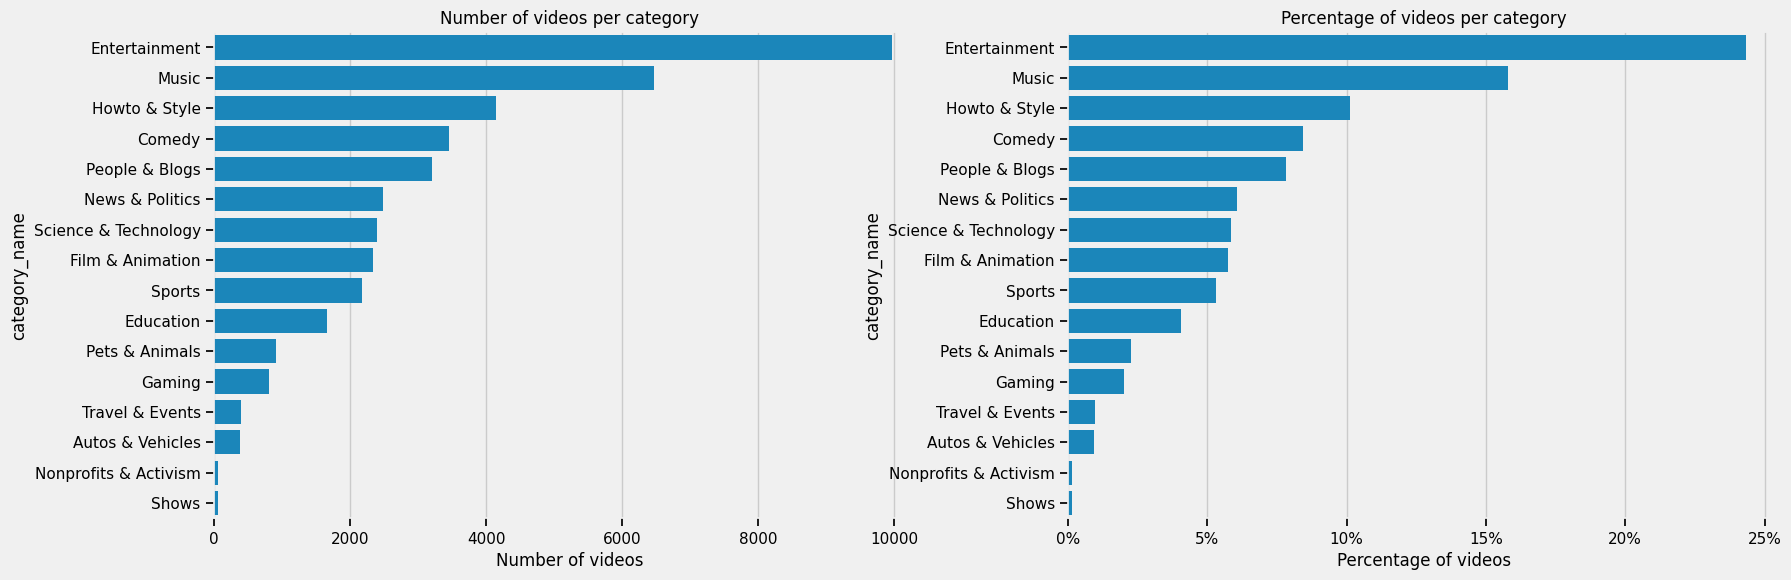

In [62]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(data=by_cat, x='len', y='category_name', ax=ax1)
sns.barplot(data=by_cat, x='percentage', y='category_name', ax=ax2)

ax1.set_title('Number of videos per category')
ax2.set_title('Percentage of videos per category')

ax1.set_xlabel('Number of videos')
ax2.set_xlabel('Percentage of videos')
ax2.set_xticklabels([f"{int(x * 100)}%" for x in ax2.get_xticks()])

plt.show()


## Categories over time

While each day usually has 200 total entries, the number of entries per category is not fixed. So let's look at the timeseries split over categories

In [63]:
# first we prepare the data:
cat_by_date = us.group_by('trending_date', 'category_name').agg(pl.len().alias('count')).sort('trending_date', 'count', descending=(False, True))
cat_by_date.head(3)

trending_date,category_name,count
date,str,u32
2017-11-14,"""Entertainment""",45
2017-11-14,"""Music""",45
2017-11-14,"""Howto & Style""",18


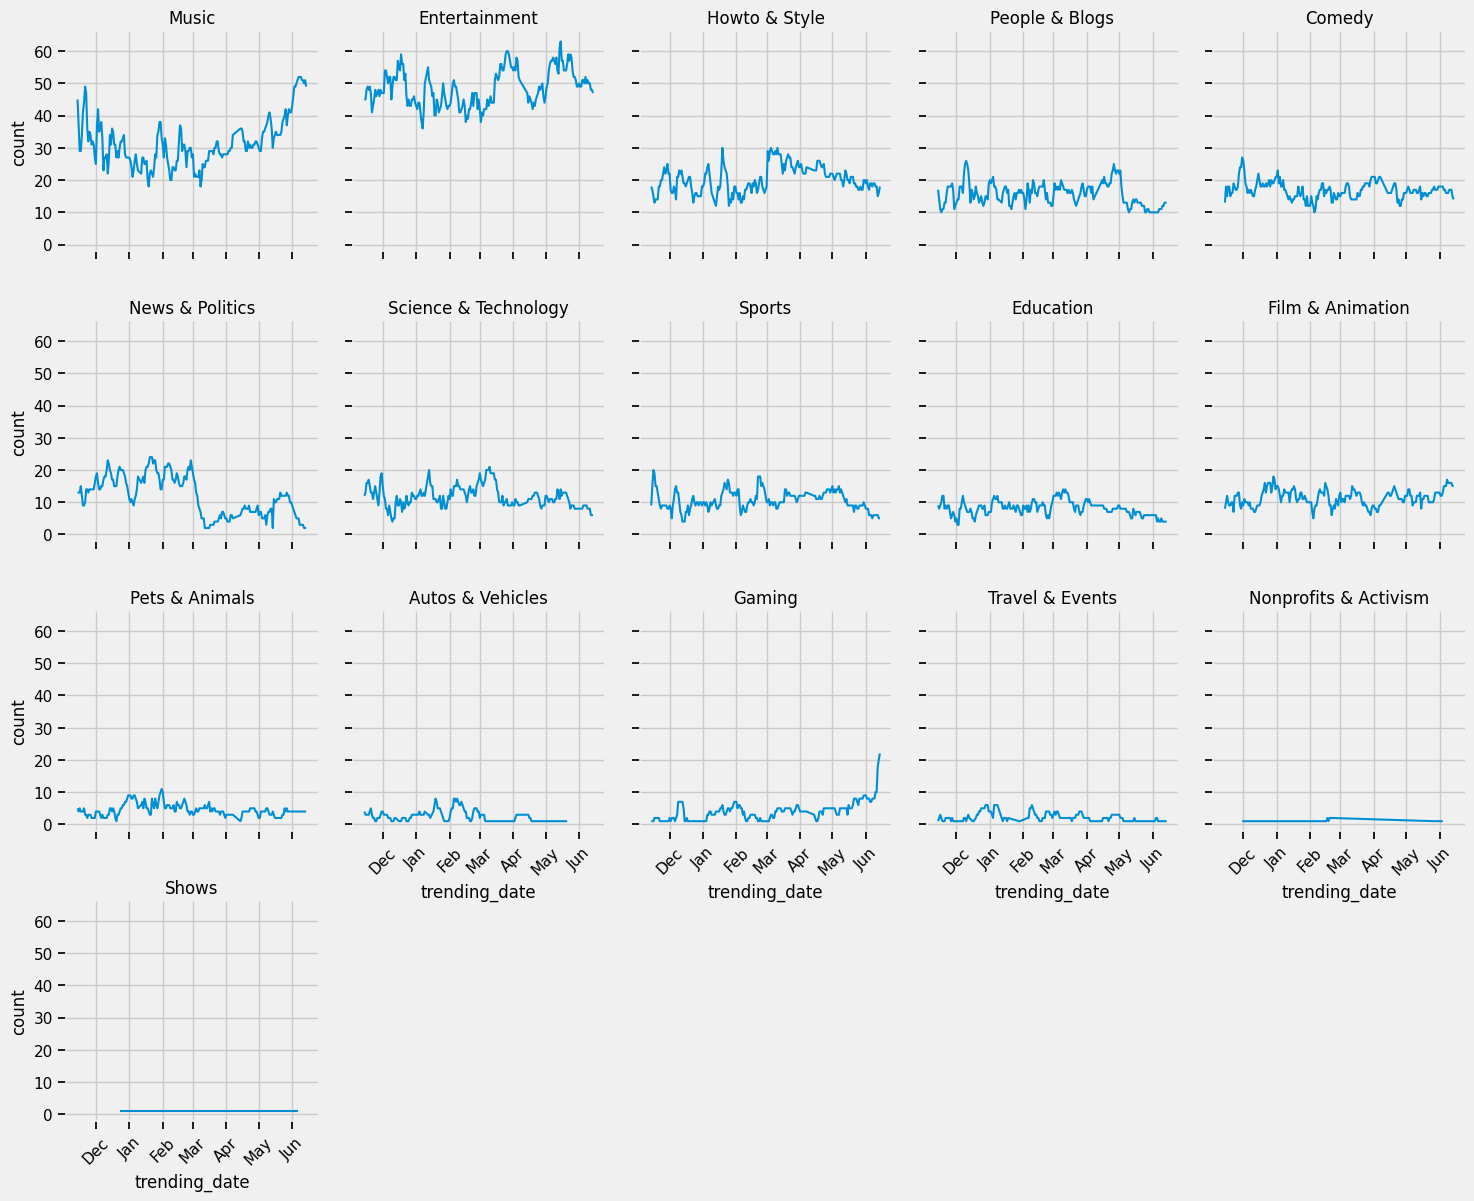

In [37]:
# next the plots:
g = sns.FacetGrid(cat_by_date, col='category_name', row_order=by_cat['category_name'], col_wrap=5, margin_titles=True)
g.map(sns.lineplot, 'trending_date', 'count')
g.set_titles(col_template="{col_name}")
for ax in g.axes.flat:
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.tick_params(axis='x', rotation=45)
plt.show()


Nothing too interesting (to my eyes), maybe except for the sudden rise of gaming towards the end of the series. Still, to get some practice, let's do another one of these overlaid plots. Also we want to group some of the small categories together to make it less confusing, which is...not as easy as it could be in Polars:

In [38]:
other_cat = by_cat.bottom_k(4, by='len').get_column('category_name')
other_row = cat_by_date.filter(pl.col('category_name').is_in(other_cat.implode())).group_by('trending_date').agg(pl.col('count').sum().alias('count')).with_columns(category_name=pl.lit('Other'))
cat_by_date = cat_by_date.remove(pl.col('category_name').is_in(other_cat.implode())).vstack(other_row.select(cat_by_date.columns)).sort('trending_date', 'count', descending=(False, True))


So lets create this graph:

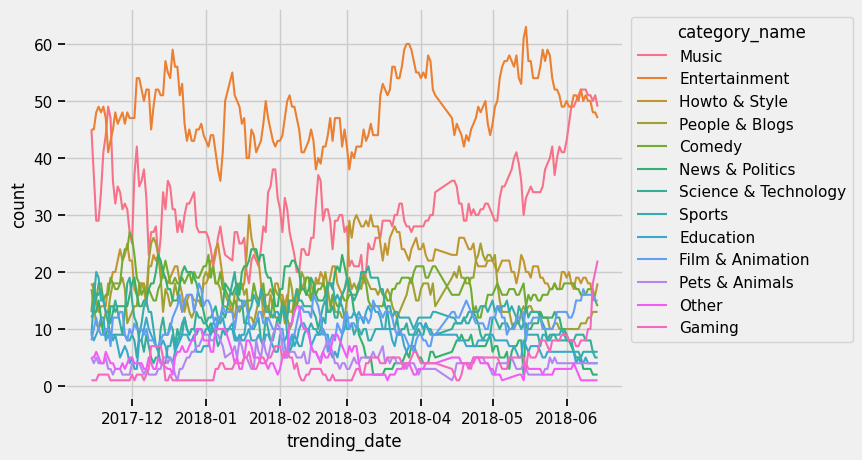

In [39]:
ax = sns.lineplot(data=cat_by_date, x='trending_date', y='count', hue='category_name')
sns.move_legend(ax, loc='upper left', bbox_to_anchor=(1, 1))

Looks busy. Let's see if we can clean that up a little bit:

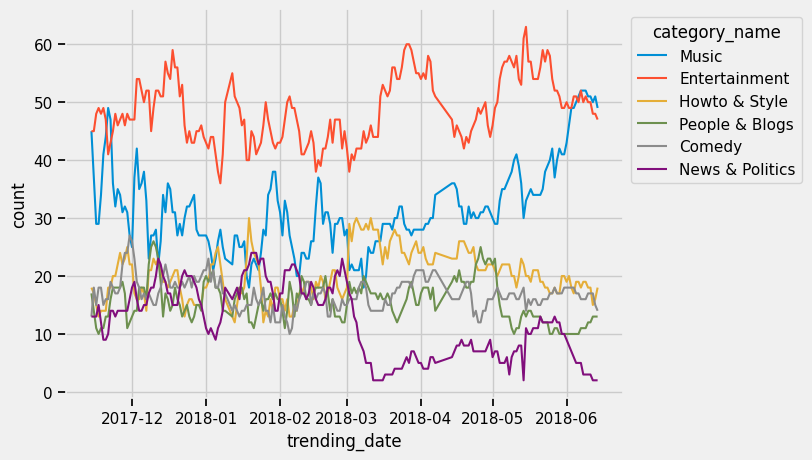

In [40]:
top_half = cat_by_date.group_by('category_name').agg(pl.sum('count')).top_k(6, by='count').get_column('category_name')

ax = sns.lineplot(data=cat_by_date.filter(pl.col('category_name').is_in(top_half.implode())), x='trending_date', y='count', hue='category_name')
sns.move_legend(ax, loc='upper left', bbox_to_anchor=(1, 1))

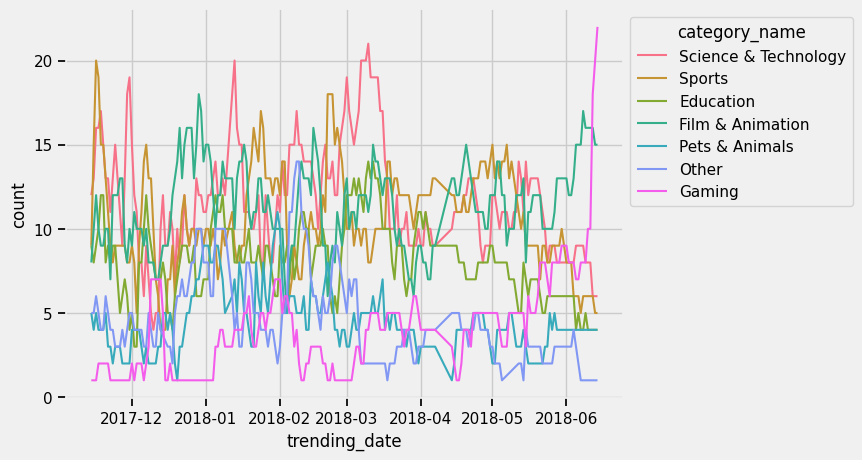

In [41]:
ax = sns.lineplot(data=cat_by_date.filter(~pl.col('category_name').is_in(top_half.implode())), x='trending_date', y='count', hue='category_name')
sns.move_legend(ax, loc='upper left', bbox_to_anchor=(1, 1))

That was...not very useful. But good practice. Let's move on.


# A Breather

So far we have looked at `trending_date`, `views`, `likes` and `dislikes` as well as the category the video is in. 

What about the other columns? Let’s pause a second and look at the bigger picture and our overall strategy:
- `video_id` does not look very promising, same goes for `thumbnail_link` (unless we want to unleash an image model onto that). Let's ignore those for now (if we would train a ML model later we might remove these columns first)
- `title` might contain a lot of rich information, but we need a strategy (or a learning algorithm) if we want to get into that. So something for later. The same goes for `tags` and `description` (although we could do some simple numerical category analysis on tags, since they are separated by the "|" character in the file)
- `channel_title` might be interesting to make sense of how the biggest channels show up in the data. 
- With `publish_time` we could look at the evolution of trending videos over time. When do they show up and for how long after being published? Similarly, we can also look at patterns in how videos appear on the trends list over multiple days. So far, we haven't even checked if there *are* any videos in the dataset that show up on multiple days
- Finally, we have the categories `comments_disabled`, `ratings_disabled` and `video_error_or_removed`. From a cursory look, most videos do not seem to have any of these flags active, which comes at no big surprise, since they would directly impede a video's ability to trend. However, there might be certain patterns here, such as more controversial videos getting these features disabled. It might also be interesting to look if some videos show up on multiple days and such flags then appear.

What are some other ideas we might want to explore?
- As I noted earlier, the dislike metrics were very spiky and went in tandem with smaller spikes in comments. It seems plausible that these spikes are caused by one or very few videos at a time. Let's look at that!
- The gaming category seemed to have a big spike in popularity towards the end. Let's see if we can figure out why!
- In the overall data, engagement metrics seemed to move mostly homogenous. Does that hold for more granular subgroups? For instance, we could look at view to like ratios across different categories, as well as comparing between videos of varying popularity
- So far we have mostly looked at counts and diagrams. We could dig deeper into the mathematical toolbox to look at variances or correlations

So we have many ideas where to go next! Where should we start?

# Success of individual videos over time
I first want to look at the popularity of videos over time. For this, I am going to use the `video_id` category, just after calling it useless! But here it is useful indeed, because we expect it to be the single reliable indicator if two entries in the database refer to the same video. Let's start by looking at how many entries in the dataset are one-offs vs show up multiple times:

In [42]:
print(f'Number of unique videos in the dataset: {us.n_unique('video_id')}, or {us.n_unique('video_id') / us.height:.2%} of all entries')


Number of unique videos in the dataset: 6351, or 15.51% of all entries


That's a lot of repeat appearances! Let's look at the distribution:

In [43]:
us.group_by('video_id').agg(pl.len().alias('nu_of_appearances')).describe()

statistic,video_id,nu_of_appearances
str,str,f64
"""count""","""6351""","6,351.0"
"""null_count""","""0""",0.0
"""mean""",null,6.447646
"""std""",null,4.642806
"""min""","""-0CMnp02rNY""",1.0
"""25%""",null,3.0
"""50%""",null,6.0
"""75%""",null,8.0
"""max""","""zzQsGL_F9_c""",30.0


So the average video shows up in the data 6.4 times (with a median of 6). 25% of videos show up three times or less, while the most popular video appeared a whopping 30 times. Let's test our hypothesis that this means 30 different days, or to put it a bit more formally, that any video can only show once per day:

In [64]:
print(f'Number of duplicate entries: {us.select('video_id', 'trending_date').is_duplicated().sum()}')
us.filter(pl.struct('video_id', 'trending_date').is_duplicated()).sort('video_id')   # have to use struct bc is_duplicated only works on series


Number of duplicate entries: 100


video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name
str,date,str,str,i64,str,str,i64,i64,i64,i64,str,bool,bool,bool,str,str
"""1RZYOeQeIXE""",2018-05-15,"""Sarah Paulson Gets Scared Duri…","""TheEllenShow""",24,"""2018-05-14T13:00:00.000Z""","""ellen|ellen degeneres|the elle…","704,786","19,880",248,669,"""https://i.ytimg.com/vi/1RZYOeQ…",false,false,false,"""Sarah Paulson agreed to play a…","""Entertainment"""
"""1RZYOeQeIXE""",2018-05-15,"""Sarah Paulson Gets Scared Duri…","""TheEllenShow""",24,"""2018-05-14T13:00:00.000Z""","""ellen|ellen degeneres|the elle…","704,786","19,880",248,669,"""https://i.ytimg.com/vi/1RZYOeQ…",false,false,false,"""Sarah Paulson agreed to play a…","""Entertainment"""
"""1U1u5aKU3AY""",2018-05-15,"""New lava fissures fuel fears o…","""CNN""",25,"""2018-05-13T19:30:53.000Z""","""latest News|Happening Now|CNN|…","241,387","1,488",251,"1,087","""https://i.ytimg.com/vi/1U1u5aK…",false,false,false,"""Three new fissures have opened…","""News & Politics"""
"""1U1u5aKU3AY""",2018-05-15,"""New lava fissures fuel fears o…","""CNN""",25,"""2018-05-13T19:30:53.000Z""","""latest News|Happening Now|CNN|…","241,387","1,488",251,"1,087","""https://i.ytimg.com/vi/1U1u5aK…",false,false,false,"""Three new fissures have opened…","""News & Politics"""
"""2PH7dK6SLC8""",2018-05-15,"""John Mayer - New Light""","""johnmayerVEVO""",10,"""2018-05-10T17:00:01.000Z""","""John|Mayer|New|Light|Snack|Mon…","1,201,548","51,670",964,"4,264","""https://i.ytimg.com/vi/2PH7dK6…",false,false,false,"""Spotify: http://radi.al/NewLig…","""Music"""
"""2PH7dK6SLC8""",2018-05-15,"""John Mayer - New Light""","""johnmayerVEVO""",10,"""2018-05-10T17:00:01.000Z""","""John|Mayer|New|Light|Snack|Mon…","1,201,548","51,670",964,"4,264","""https://i.ytimg.com/vi/2PH7dK6…",false,false,false,"""Spotify: http://radi.al/NewLig…","""Music"""
"""3g5O-kT9m8k""",2018-05-15,"""$1000 Survival Kit in a Case""","""CrazyRussianHacker""",28,"""2018-05-13T18:51:13.000Z""","""$1000 Survival Kit|Survival Ki…","1,289,899","51,318","1,359","4,332","""https://i.ytimg.com/vi/3g5O-kT…",false,false,false,"""$15 Survival Kit Unboxing - ht…","""Science & Technology"""
"""3g5O-kT9m8k""",2018-05-15,"""$1000 Survival Kit in a Case""","""CrazyRussianHacker""",28,"""2018-05-13T18:51:13.000Z""","""$1000 Survival Kit|Survival Ki…","1,289,899","51,318","1,359","4,332","""https://i.ytimg.com/vi/3g5O-kT…",false,false,false,"""$15 Survival Kit Unboxing - ht…","""Science & Technology"""
"""4oqvNR1o3Zo""",2018-05-15,"""24 HOUR BOX FORT PRISON ESCAPE…","""Papa Jake""",24,"""2018-05-13T16:42:33.000Z""","""box fort|fort|kids|funny|fun|n…","1,030,616","20,251","3,290","3,567","""https://i.ytimg.com/vi/4oqvNR1…",false,false,false,"""In Todays 24 hour Box Fort vid…","""Entertainment"""


Wait! All of these videos seem to be exactly duplicated once. What's more, they are all on the same date (15 May 2018). Let's drop the duplicates, even though that means this day will have fewer data points.

In [65]:
length = us.height
print(f'Number of rows before removal of duplicates: {length}')
us = us.unique(subset=['video_id', 'trending_date'])    # There were two extra duplicates where viewer counts and similar metrics were very slightly different, so I want to remove those as well
print(f'Number of rows after removal of duplicates: {us.height}. {length - us.height} duplicates removed')

Number of rows before removal of duplicates: 40949
Number of rows after removal of duplicates: 40899. 50 duplicates removed


Let's get on with the analyis. 

In [66]:
repeat_showings = us.group_by('video_id').agg(pl.len().alias('nu_of_appearances')).group_by('nu_of_appearances').agg(pl.len().alias('nu_of_videos')).sort('nu_of_appearances')
repeat_showings

nu_of_appearances,nu_of_videos
u32,u32
1,708
2,527
3,586
4,549
5,687
6,766
7,710
8,353
9,256


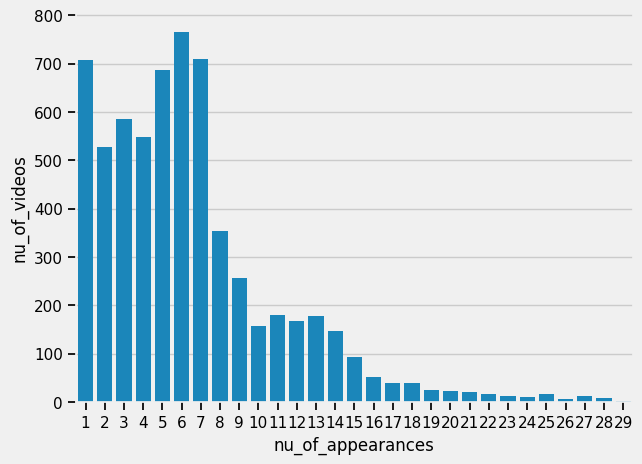

In [67]:
sns.barplot(data=repeat_showings, x='nu_of_appearances', y='nu_of_videos')
plt.show()

We can see here that most videos show up between 1 and 7 times. However, there are different ways to split the turkey: Since we are looking at data aggregation, we have to make a sampling choice that will affect the data statistics. Instead of grouping by video id's (which resembles the perspective of a video creator for instance, who asks himself how well his video might do) we could choose a different perspective: We could look at each row of our dataframe, asking the question: For any given appearance in the trending-list, how many appearances will that video make overall? This will automatically weight videos higher that appear multiple times. 

A third, perhaps most natural, perspective, would be to take the perspective of the viewer and aggregate videos by views (so a video with 1 million views will appear in the statistic 1 million times). 

Perhaps we can do that later, but for now let's work with the data that we have, which is appearances in the list and work from that:

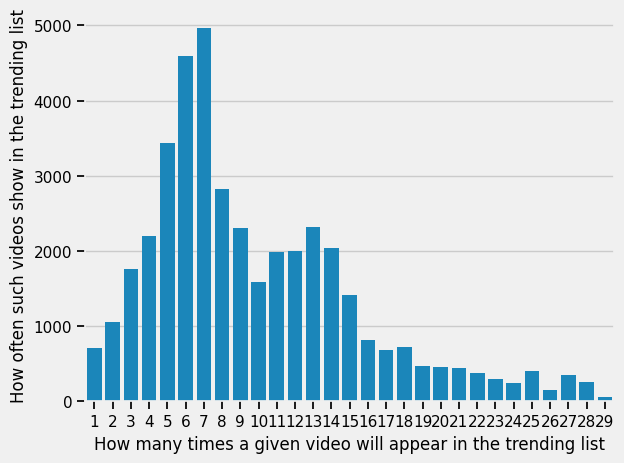

In [68]:
ax = sns.barplot(data=repeat_showings.with_columns(appearances_by_appearance = pl.col('nu_of_appearances') * pl.col('nu_of_videos')), x='nu_of_appearances', y='appearances_by_appearance')
ax.set_ylabel('How often such videos show in the trending list')
ax.set_xlabel('How many times a given video will appear in the trending list')
plt.tight_layout()
plt.show()

The latter diagram shows a much more right-skewed distribution. Let's see if we can bear this out with hard statistics:

In [69]:
# Calculate statistics *per unique video*:
appear_by_video = us.group_by('video_id').agg(pl.len().alias('nu_of_appearances'))

#Calculate statistics *per appearance in our dataframe*:
us_with_appearances = us.with_columns(pl.len().over('video_id').alias('no_appearances'))

display(appear_by_video['nu_of_appearances'].describe())
display(us_with_appearances['no_appearances'].describe())

statistic,value
str,f64
"""count""","6,351.0"
"""null_count""",0.0
"""mean""",6.439773
"""std""",4.62851
"""min""",1.0
"""25%""",3.0
"""50%""",6.0
"""75%""",8.0
"""max""",29.0


statistic,value
str,f64
"""count""","40,899.0"
"""null_count""",0.0
"""mean""",9.765936
"""std""",5.716068
"""min""",1.0
"""25%""",6.0
"""50%""",8.0
"""75%""",13.0
"""max""",29.0


In [70]:
# lets add that column for good:
us = us_with_appearances

In [71]:
# lets look at the top 10 most frequently appearing videos:
us.sort('no_appearances', 'trending_date', descending=True).unique(subset='video_id', keep='first', maintain_order=True).head(10)

video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name,no_appearances
str,date,str,str,i64,str,str,i64,i64,i64,i64,str,bool,bool,bool,str,str,u32
"""j4KvrAUjn6c""",2018-06-11,"""WE MADE OUR MOM CRY...HER DREA…","""Lucas and Marcus""",24,"""2018-05-13T18:03:56.000Z""","""Lucas and Marcus|Marcus and Lu…","10,381,263","163,325","20,892","25,323","""https://i.ytimg.com/vi/j4KvrAU…",false,false,false,"""BEST MOM EVER! WANT TO SEE US …","""Entertainment""",29
"""8h--kFui1JA""",2018-06-08,"""Sam Smith - Pray (Official Vid…","""SamSmithWorldVEVO""",10,"""2018-05-09T17:00:00.000Z""","""Sam|Smith|Pray|Capitol|Pop""","20,934,803","359,012","9,294","12,451","""https://i.ytimg.com/vi/8h--kFu…",false,false,false,"""Stream, Download and Listen to…","""Music""",29
"""6S9c5nnDd_s""",2018-06-12,"""Bohemian Rhapsody | Teaser Tra…","""20th Century Fox""",1,"""2018-05-15T13:01:12.000Z""","""Trailer|bohemian rhapsody|quee…","13,619,534","347,100","6,923","19,977","""https://i.ytimg.com/vi/6S9c5nn…",false,false,false,"""Visit http://www.PutMeInBohemi…","""Film & Animation""",28
"""QBL8IRJ5yHU""",2018-06-11,"""Why I'm So Scared (being mysel…","""grav3yardgirl""",26,"""2018-05-14T19:00:01.000Z""","""beauty|how to|makeup|howto|sty…","3,811,648","306,473","13,441","52,719","""https://i.ytimg.com/vi/QBL8IRJ…",false,false,false,"""I will never be able to say Th…","""Howto & Style""",28
"""MAjY8mCTXWk""",2018-06-11,"""周杰倫 Jay Chou【不愛我就拉倒 If You Don…","""杰威爾音樂 JVR Music""",10,"""2018-05-14T15:59:47.000Z""","""周杰倫|Jay|Chou|周董|周杰伦|周傑倫|杰威尔|周周…","21,957,640","140,214","10,716","15,418","""https://i.ytimg.com/vi/MAjY8mC…",false,false,false,"""MV點閱率破華語歌曲紀錄，首日點閱突破200萬，三週已狂飆2…","""Music""",28
"""NBSAQenU2Bk""",2018-06-11,"""Rooster Teeth Animated Adventu…","""Rooster Teeth""",1,"""2018-05-14T13:00:01.000Z""","""Rooster Teeth|RT|animation|tel…","751,768","25,434",173,769,"""https://i.ytimg.com/vi/NBSAQen…",false,false,false,"""Millie is invited to help out …","""Film & Animation""",28
"""r-3iathMo7o""",2018-06-11,"""The ULTIMATE $30,000 Gaming PC…","""Unbox Therapy""",28,"""2018-05-13T19:00:25.000Z""","""gaming setup|gaming|setup|fort…","6,995,168","143,678","10,925","17,444","""https://i.ytimg.com/vi/r-3iath…",false,false,false,"""Fortnite, PUBG, Far Cry 5? Whi…","""Science & Technology""",28
"""t4pRQ0jn23Q""",2018-06-11,"""YoungBoy Never Broke Again Goe…","""Complex""",24,"""2018-05-14T14:00:03.000Z""","""sneakerhead|complex|complex or…","4,654,027","116,674","5,707","14,279","""https://i.ytimg.com/vi/t4pRQ0j…",false,false,false,"""YoungBoy Never Broke Again goe…","""Entertainment""",28
"""ulNswX3If6U""",2018-06-09,"""Selena Gomez - Back To You (Ly…","""Selena Gomez""",1,"""2018-05-10T16:00:11.000Z""","""selena gomez|13 reasons why|ba…","54,863,912","922,355","18,037","41,774","""https://i.ytimg.com/vi/ulNswX3…",false,false,false,"""Get 'Back To You,' out now: ht…","""Film & Animation""",28


let's see if the popularity of a category and the longevity of its representatives in the list shows interesting patterns:

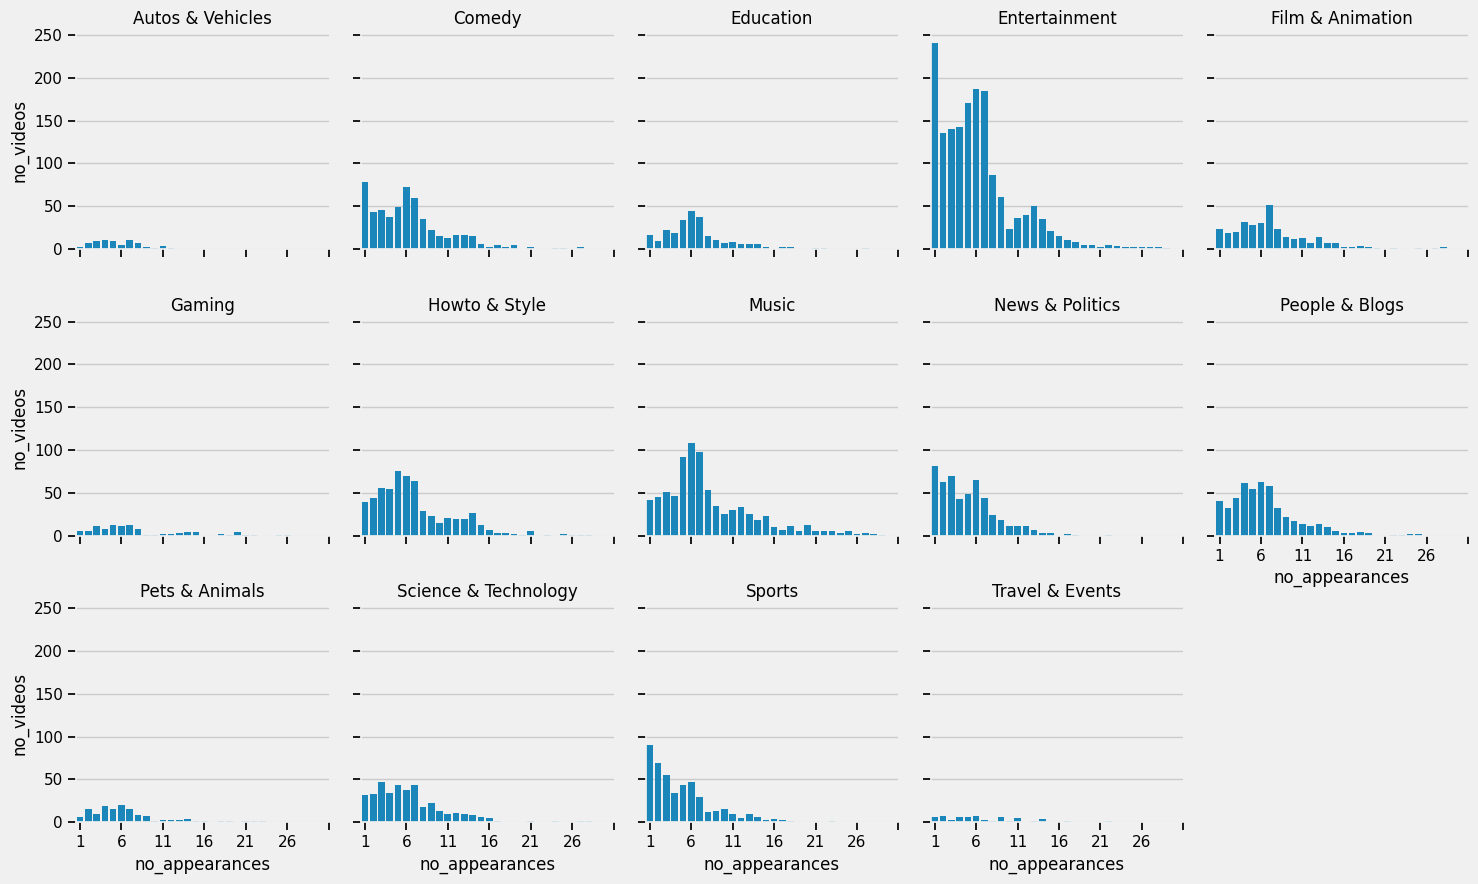

In [72]:
app_by_cat = us.select('video_id', 'category_name', 'no_appearances').unique()\
          .group_by('category_name', 'no_appearances').agg(pl.len().alias('no_videos')).sort('category_name', 'no_appearances')

app_by_cat_small = app_by_cat.filter(pl.col('no_videos').sum().over('category_name') > 50)

g = sns.FacetGrid(app_by_cat_small, col='category_name', row_order=list(by_cat['category_name']), col_wrap=5, margin_titles=False)
g.map(sns.barplot, 'no_appearances', 'no_videos', order=range(1, 30))
g.set_titles(col_template="{col_name}")
g.set(xticks=range(0,31,5))
plt.show()


These charts show some interesting trends. 
- Most categories show the wide distribution we already saw in the aggregated data, with a peak around 6 days and a long tail afterwards
- **Sports** and **News & Politics** are different, showin a triangular shape, with most videos disappearing very quickly. This probably reflects the news-driven nature of these categories: Breaking news are hot, but get replaced quickly by the newscycle.
- Conversely, categories like **Education, Film & Animation, Gaming, Science & Technology** and **Travel & Events** seem to rely more on a few videos enjoying outsized, lasting success, reflecting a slower burning kind of virality. 
- The most popular categories, which include **Entertainment, Music, Howto & Style** as well as **People & Blogs** are somewhere in the middle

I am tempted to identify 4 clusters based on this:
- A fast-moving news cluster around Sports, News and Politics
- An entertainment industry content cluster around Entertainment and Music
- A social media cluster around Howto & Style and People & Blogs as well as Gaming
- An edutainment cluster covering the rest of the gang

Tentative but intruiging, although, let's be real, the signal here isn't THAT strong (except for the News part).

# Looking at the Dislike Spikes

Let's do what I've been itching to do since I saw it in the diagram: Figure out what's going on with those dislike spikes. To recall, there were two big (and various smaller) spikes in the dislike category

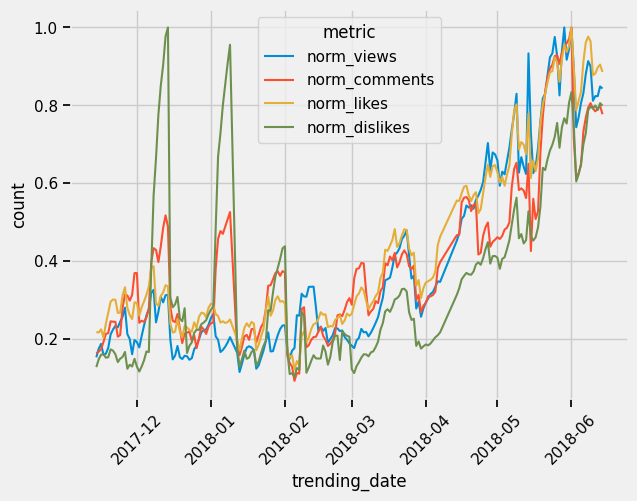

In [73]:
long_norm = by_date.unpivot(index='trending_date', on=['norm_views', 'norm_comments', 'norm_likes', 'norm_dislikes'], variable_name='metric', value_name='count')

sns.lineplot(data=long_norm, x='trending_date', y='count', hue='metric')
plt.xticks(rotation=45)
plt.show()

## How whale-y are engagement metrics?

Before we dive into the individual videos driving the spikes I want to ground this with some baselines for the chunkiness one might expect from dislikes in particular and engagement metrics in general. We have 200 unique videos per day. How (un-)equal are those videos contributing to our aggregate stats? Do a few whales drive the show? Let's take a look:

The idea here is that we will look at the relative contribution of the top 1 biggest, top 3, top 10, top 50 and top 100 videos to the aggregate stats for each of our metrics, averaged over all days in our sample. Our end result should be a pivot table (which we haven't used yet in this notebook):

In [74]:
metrics = ['views', 'likes', 'dislikes', 'comment_count']
top_ns = [1, 3, 10, 50, 100]

# relative contributions:
us_rel = us.with_columns(**{f'rel_{metric}' : pl.col(metric) / pl.col(metric).sum().over('trending_date') for metric in metrics})

# aggregation:
top_n_contributions = pl.DataFrame({'top_n_contribution': top_ns})
for metric in metrics:
    top_n_contributions = top_n_contributions.with_columns(pl.Series(f'{metric}', 
        [us_rel.group_by('trending_date').agg(pl.col(f'rel_{metric}').top_k(n).sum()).select(f'rel_{metric}').mean().item() for n in top_ns]))
        
top_n_contributions


top_n_contribution,views,likes,dislikes,comment_count
i64,f64,f64,f64,f64
1,0.131101,0.13973,0.232532,0.195911
3,0.262511,0.279995,0.373119,0.337071
10,0.45736,0.488506,0.568985,0.526175
50,0.796002,0.831972,0.859897,0.838204
100,0.928048,0.94694,0.955623,0.949023


That was a lot of work! But we got the results we were looking for: The typical video leading the dislike-statistics on any given day would hold around 23% of total dislikes. That's very substantial, but a single video responsible for a spike to many times the previous days total dislike count would still be somewhat unexpected given these statistics. To note: Dislikes are a bit more concentrated than other metrics, followed by comment count. Among all metrics, the Top 10 videos typically have around half of all engagement stats. Once you go beyond the Top 50, most of the cake has been accounted for and there are only morsels left.

## Let's zoom into the spiky periods to see what's going on:


In [75]:
us.group_by('trending_date').agg(pl.sum('dislikes').alias('total_dislikes'), pl.sum('comment_count').alias('total_comments'), pl.sum('views').alias('total_views')).sort('trending_date')

trending_date,total_dislikes,total_comments,total_views
date,i64,i64,i64
2017-11-14,"270,876","691,402","185,435,246"
2017-11-15,"313,577","709,009","212,445,216"
2017-11-16,"338,755","735,962","227,365,391"
2017-11-17,"341,176","814,596","193,541,711"
2017-11-18,"322,349","901,370","196,846,875"
2017-11-19,"324,972","910,415","215,052,284"
2017-11-20,"367,519","1,038,231","257,000,111"
2017-11-21,"360,554","1,034,750","272,366,796"
2017-11-22,"340,612","1,033,128","283,346,688"


### "Staring at tables" analysis
The first spike started on December 7th 2017, when within a day dislikes rose from around 350,000 to over 800,000. They peaked a week later on December 14 at over 2.1 million - the next day they had fallen back to around 650,000. What happened? Did the offending video fall out of the charts? We’ll find out.

But first, let’s identify the second spike from the data: On January 3rd 2018 dislikes suddenly rose from around 600,000 to about 1 million, rose steadily over the next days, peaked at a little over 2 million on January 9 - before falling back to 377,000 on January 12, the lowest value in 3 weeks. There is a little data gap here, the dataset omits data from January 10 and 11.

To note also that in both cases, the total comment count rose (and fell) in tandem with the dislikes while there is no clear trend in total viewership numbers. So are scandals good for engagement as is often claimed? The overall data doesn't necessarily bear that out. At least it doesn't seem to be 'make or break' for the platforms.

Some smaller disruptions: On Feb 2 dislikes *fall* from 930,000 to 359,000 in a day.

And rising from the mid 400,000’s,  starting April 14 we have a slow and steady rise to around 1.7 million by the end of the data set in June with only little spikes in between. Is that meaningful? Maybe not with respect to dislike data in particular, since all other engagement metrics (views, likes, comments)  rose in the same period the same amount, if not more, as we could see in the diagram above.

### Data dive

Now let's dive into the actual spikes:

In [76]:
us.filter(pl.col('trending_date').is_between(pl.date(2017, 12, 6), pl.date(2017, 12, 15))).sort('dislikes', descending=True).drop('video_id', 'tags', 'thumbnail_link', 'description').head(10)

trending_date,title,channel_title,category_id,publish_time,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category_name,no_appearances
date,str,str,i64,str,i64,i64,i64,i64,bool,bool,bool,str,u32
2017-12-14,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","149,376,127","3,093,544","1,643,059","810,698",false,false,false,"""Entertainment""",8
2017-12-13,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","137,843,120","3,014,471","1,602,383","817,582",false,false,false,"""Entertainment""",8
2017-12-12,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","125,432,237","2,912,702","1,545,015","807,558",false,false,false,"""Entertainment""",8
2017-12-11,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","113,874,632","2,811,215","1,470,383","787,174",false,false,false,"""Entertainment""",8
2017-12-10,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","100,911,567","2,656,659","1,353,647","682,890",false,false,false,"""Entertainment""",8
2017-12-09,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","75,969,469","2,251,797","1,127,798","827,755",false,false,false,"""Entertainment""",8
2017-12-08,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","52,611,730","1,891,799","884,944","702,769",false,false,false,"""Entertainment""",8
2017-12-07,"""YouTube Rewind: The Shape of 2…","""YouTube Spotlight""",24,"""2017-12-06T17:58:51.000Z""","24,782,158","1,149,185","483,924","462,103",false,false,false,"""Entertainment""",8
2017-12-15,"""Logan Paul - SANTA DISS TRACK …","""Logan Paul Vlogs""",24,"""2017-12-10T21:32:44.000Z""","13,445,632","917,951","123,922","156,083",false,false,false,"""Entertainment""",7


Ok, the Youtube Rewind video of 2017. I kinda remember that. Here we have a single video garnering 1.6 million dislikes by December 14, as well as 800,000 comments. That explains this spike. 

Actually, I just looked it up and the "infamous" Rewind video was the one from 2018, one year later. But I guess the dislike metric of 2017 was a harbinger of things to come.

In [77]:
us.filter(pl.col('trending_date').is_between(pl.date(2018, 1, 3), pl.date(2018, 1, 11))).sort('dislikes', descending=True).drop('video_id', 'tags', 'thumbnail_link', 'description').head(10)

trending_date,title,channel_title,category_id,publish_time,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category_name,no_appearances
date,str,str,i64,str,i64,i64,i64,i64,bool,bool,bool,str,u32
2018-01-09,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","37,539,570","1,402,578","1,674,420","1,361,580",false,false,false,"""Entertainment""",7
2018-01-08,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","35,983,135","1,370,845","1,611,043","1,321,281",false,false,false,"""Entertainment""",7
2018-01-07,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","33,998,325","1,325,296","1,517,520","1,281,094",false,false,false,"""Entertainment""",7
2018-01-06,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","31,675,237","1,275,142","1,415,777","1,194,249",false,false,false,"""Entertainment""",7
2018-01-05,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","28,407,744","1,204,072","1,278,887","1,238,817",false,false,false,"""Entertainment""",7
2018-01-04,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","23,389,090","1,082,422","1,065,772","1,059,651",false,false,false,"""Entertainment""",7
2018-01-03,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","13,305,605","835,378","629,120","733,373",false,false,false,"""Entertainment""",7
2018-01-09,"""Bruno Mars - Finesse (Remix) […","""Bruno Mars""",10,"""2018-01-04T04:49:43.000Z""","43,067,983","1,717,175","61,567","123,379",false,false,false,"""Music""",7
2018-01-08,"""Bruno Mars - Finesse (Remix) […","""Bruno Mars""",10,"""2018-01-04T04:49:43.000Z""","37,728,801","1,629,944","56,304","116,255",false,false,false,"""Music""",7


What about this one? A Logan Paul video titled So Sorry with 1.6 million dislikes and 1.3 million comments. Yikes. That's the same number of dislikes and much more comments than the Youtube Rewind video. And unlike in the Youtube Rewind video the dislikes actually outnumber the likes, a feat in and of itself.

Let's look that up btw: How many videos in the dataset have more dislikes than likes?

In [78]:
us.filter(pl.col('dislikes') > pl.col('likes')).unique('video_id', keep='last').drop('video_id', 'tags', 'thumbnail_link', 'description').sort('dislikes', descending=True)

trending_date,title,channel_title,category_id,publish_time,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category_name,no_appearances
date,str,str,i64,str,i64,i64,i64,i64,bool,bool,bool,str,u32
2018-01-06,"""So Sorry.""","""Logan Paul Vlogs""",24,"""2018-01-02T16:42:21.000Z""","31,675,237","1,275,142","1,415,777","1,194,249",false,false,false,"""Entertainment""",7
2017-12-21,"""PSA from Chairman of the FCC A…","""Daily Caller""",22,"""2017-12-13T22:52:57.000Z""","1,205,682","9,572","228,426","29,634",false,false,false,"""People & Blogs""",3
2018-02-22,"""Fergie Performs The U.S. Natio…","""MLG Highlights""",17,"""2018-02-19T01:37:11.000Z""","17,030,271","41,743","141,315","53,209",false,false,false,"""Sports""",7
2017-12-17,"""The FCC repeals its net neutra…","""Washington Post""",25,"""2017-12-14T18:49:06.000Z""","1,242,998","5,884","130,836","23,297",false,false,false,"""News & Politics""",4
2018-06-09,"""#ProudToCreate: Pride 2018""","""YouTube Spotlight""",24,"""2018-06-07T19:08:51.000Z""","1,074,997","43,153","110,997","81,289",false,false,false,"""Entertainment""",7
2017-12-17,"""Judge Roy Moore Campaign State…","""Roy Moore for Senate""",22,"""2017-12-14T03:04:05.000Z""","753,386","4,167","57,285",0,true,false,false,"""People & Blogs""",8
2017-11-19,"""Selling My iPhone X To a Machi…","""TechSmartt""",28,"""2017-11-14T00:45:15.000Z""","3,716,275","43,697","45,910","12,489",false,false,false,"""Science & Technology""",7
2018-02-18,"""I Feel Pretty Trailer #1 | Mov…","""Movieclips Trailers""",1,"""2018-02-08T20:00:03.000Z""","1,071,466","10,749","38,082","7,557",false,false,false,"""Film & Animation""",10
2018-02-20,"""Fergie's national anthem draws…","""ESPN""",17,"""2018-02-19T12:42:36.000Z""","2,762,839","14,362","37,877","21,507",false,false,false,"""Sports""",1


The answer is 122! And it's videos of all sizes too. If you go near the bottom, some of the videos only have maybe 2000 views with one like and three dislikes. Makes you wonder how the algorithm that picks "trending" videos works, which is what we are going to do next.

## What's going on with small videos in the dataset?

Take the third entry from the bottom: MTB Skills - Technical Climb by Geoff Mallinson. The video was originally uploaded in 2015, yet it appeared three times in our dataset, with less than 5000 views and below 5 likes/dislikes/comments. How? Why? And it's not like the video is in a niche category, it's in Entertainment! I cannot really understand what is going on here. Let's look at that video in more detail:

In [79]:
us.filter(pl.col('channel_title') == 'Geoff Mallinson')

video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name,no_appearances
str,date,str,str,i64,str,str,i64,i64,i64,i64,str,bool,bool,bool,str,str,u32
"""qDI8LnPq3VY""",2018-01-27,"""MTB Skills - Technical Climb""","""Geoff Mallinson""",24,"""2015-04-02T12:41:47.000Z""","""[none]""","4,802",2,4,1,"""https://i.ytimg.com/vi/qDI8LnP…",false,false,false,"""Riding some of the single trac…","""Entertainment""",3
"""qDI8LnPq3VY""",2018-01-26,"""MTB Skills - Technical Climb""","""Geoff Mallinson""",24,"""2015-04-02T12:41:47.000Z""","""[none]""","4,681",2,3,1,"""https://i.ytimg.com/vi/qDI8LnP…",false,false,false,"""Riding some of the single trac…","""Entertainment""",3
"""qDI8LnPq3VY""",2018-01-28,"""MTB Skills - Technical Climb""","""Geoff Mallinson""",24,"""2015-04-02T12:41:47.000Z""","""[none]""","4,880",2,4,1,"""https://i.ytimg.com/vi/qDI8LnP…",false,false,false,"""Riding some of the single trac…","""Entertainment""",3


A three year old (at the time) video that shows up out of nowhere on three consecutive days, collects maybe 100 views per day and then vanishes agin. Btw. it is a slo-mo video of mountain bikers trying (and mostly failing) to climb up on a certain spot in the woods.

Ok. Let's look at more data. How about we start by looking at the number of small videos in the dataset, let's say with views < 10,000

In [80]:
us.filter(pl.col('views') < 10000).unique('video_id').sort('no_appearances', descending=True).drop('tags', 'thumbnail_link', 'description')

video_id,trending_date,title,channel_title,category_id,publish_time,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category_name,no_appearances
str,date,str,str,i64,str,i64,i64,i64,i64,bool,bool,bool,str,u32
"""WQd6x4KmVhA""",2017-12-23,"""Where Were You When You Found …","""Billboard""",10,"""2017-12-22T15:58:16.000Z""","6,377",414,16,35,false,false,false,"""Music""",11
"""teA0Z7ltRSY""",2017-12-23,"""Apple Sued Over Slowing Down i…","""CBS New York""",25,"""2017-12-22T04:31:29.000Z""","8,120",199,9,130,false,false,false,"""News & Politics""",11
"""WIWb8f1WIyQ""",2017-12-25,"""PART 1 | Gwen Stefani with Bla…","""Famous Celebrities Snaps""",24,"""2017-12-25T03:08:33.000Z""","5,751",89,49,58,false,false,false,"""Entertainment""",11
"""drg74wOy8z8""",2017-12-24,"""Freak Show – Official Trailer …","""IFC Films""",1,"""2017-12-22T19:30:00.000Z""","9,109",112,46,10,false,false,false,"""Film & Animation""",11
"""IoqDYnn7VKA""",2017-12-30,"""Original Bellas rehearsal vide…","""Rebel Wilson""",23,"""2017-12-29T17:32:51.000Z""","6,624",412,18,40,false,false,false,"""Comedy""",9
"""DzNwinmBawo""",2018-02-15,"""The FBI came to visit me today…","""BenTheBondsman""",22,"""2018-02-15T03:15:34.000Z""","9,015",894,58,385,false,false,false,"""People & Blogs""",9
"""6J-D86wfxiE""",2018-02-14,"""Chadwick Boseman gets emotiona…","""SiriusXM""",25,"""2018-02-13T21:00:41.000Z""","5,488",702,49,137,false,false,false,"""News & Politics""",9
"""doHVMJnuvDA""",2017-12-28,"""Lost in Light II""","""Sriram Murali""",28,"""2017-08-15T18:26:40.000Z""","7,938",430,9,42,false,false,false,"""Science & Technology""",9
"""bJje-B9YLIU""",2017-12-31,"""The 75th Annual Golden Globes …","""NBC""",24,"""2017-12-22T14:00:02.000Z""","6,279",25,10,8,false,false,false,"""Entertainment""",9


So 351 videos total with less than 10,000 views. Remember we had around 6,300 unique videos total in the dataset, so that's thereabout's 5% of all trending videos. Some of these small videos show up 6,7,8...up to 11 times in the dataset (isn't it handy we made that no_appearances column earlier)...which would be bonkers if the video in question never got above 10,000 views. It is, however, possible that the video first appeared in the dataset when it was still small, but exploded in popularity afterwards. In this case, that would be proof of the algorithm working. Which is it? Let's find out!

We first start with creating a subset of videos that appear in the dataset while small AND that appeared multiple times (let's say 5+). How many videos are there that fit these criteria? That will determine if we can plot these videos trajectory individually or we need a different approach:

In [81]:
us.filter((pl.col('views') < 10000) & (pl.col('no_appearances') >= 5)).unique('video_id').height

99

99 videos...that's a bit much, but I am eager to try out this visualization. We will plot a special kind of overlaid timeseries, where each video gets a lineplot showing its total views over time. And on the x-axis, 0 represents every videos first appearance in the dataset, going day-by-day from there. If it's too busy we can reduce the number of lines later. 

In [82]:
small_longevity_video_ids = us.filter((pl.col('views') < 10000) & (pl.col('no_appearances') >= 5)).unique('video_id').select('video_id')
small_longevity_videos = us.join(small_longevity_video_ids, on='video_id', how='semi').sort('video_id', 'trending_date')
small_longevity_videos = small_longevity_videos.with_columns(days_since_first_appearance=
                                                             (pl.col('trending_date') - pl.col('trending_date').min().over('video_id')).dt.total_days()) 

# let's add this column to the full df as well:
us = us.with_columns(days_since_first_appearance = (pl.col('trending_date') - pl.col('trending_date').min().over('video_id')).dt.total_days())

small_longevity_videos.select('video_id', 'title', 'views', 'trending_date', 'days_since_first_appearance').head()

video_id,title,views,trending_date,days_since_first_appearance
str,str,i64,date,i64
"""-37nIo_tLnk""","""Christmas Day 2000""","2,863",2017-12-26,0
"""-37nIo_tLnk""","""Christmas Day 2000""","2,987",2017-12-27,1
"""-37nIo_tLnk""","""Christmas Day 2000""","3,052",2017-12-28,2
"""-37nIo_tLnk""","""Christmas Day 2000""","3,085",2017-12-29,3
"""-37nIo_tLnk""","""Christmas Day 2000""","3,111",2017-12-30,4


<function matplotlib.pyplot.show(close=None, block=None)>

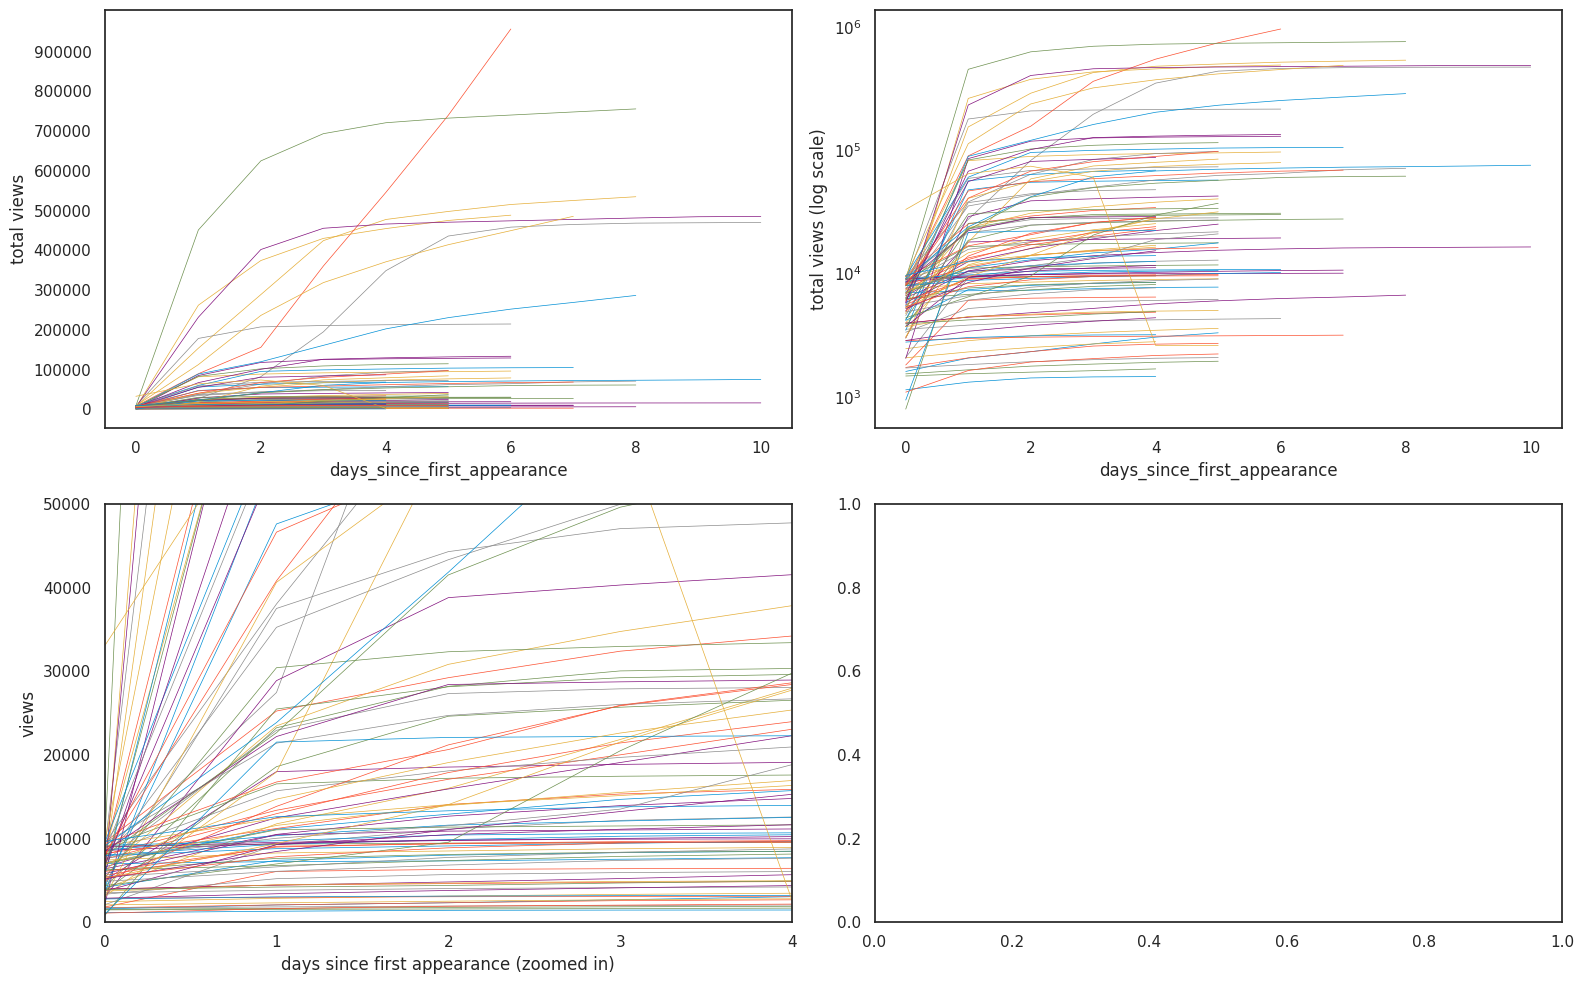

In [83]:

with sns.axes_style("white"), sns.plotting_context(rc={"lines.linewidth": 0.5}):
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2,2, figsize=(16, 10))

    for i in small_longevity_video_ids['video_id']:
        video_i = small_longevity_videos.filter(pl.col('video_id') == i)
        sns.lineplot(video_i, x='days_since_first_appearance', y='views', ax=ax1)
        sns.lineplot(video_i, x='days_since_first_appearance', y='views', ax=ax2)
        sns.lineplot(video_i, x='days_since_first_appearance', y='views', ax=ax3)

    ax1.set_ylabel('total views')
    ax2.set_ylabel('total views (log scale)')

    ax1.set_yticks(range(0, 1000000, 100000))
    ax2.set_yscale('log')

    ax3.set_xticks(range(0, 5, 1))
    # ax3.set_yticks(range(0,150001, 15000))
    ax3.set_xlim(0,4)
    ax3.set_ylim(0,50000)
    ax3.set_xlabel('days since first appearance (zoomed in)')

plt.tight_layout()
plt.show

That looks like we have...some successful, some less so. It looks a bit messy. What if we re-run the code with fewer videos?

<function matplotlib.pyplot.show(close=None, block=None)>

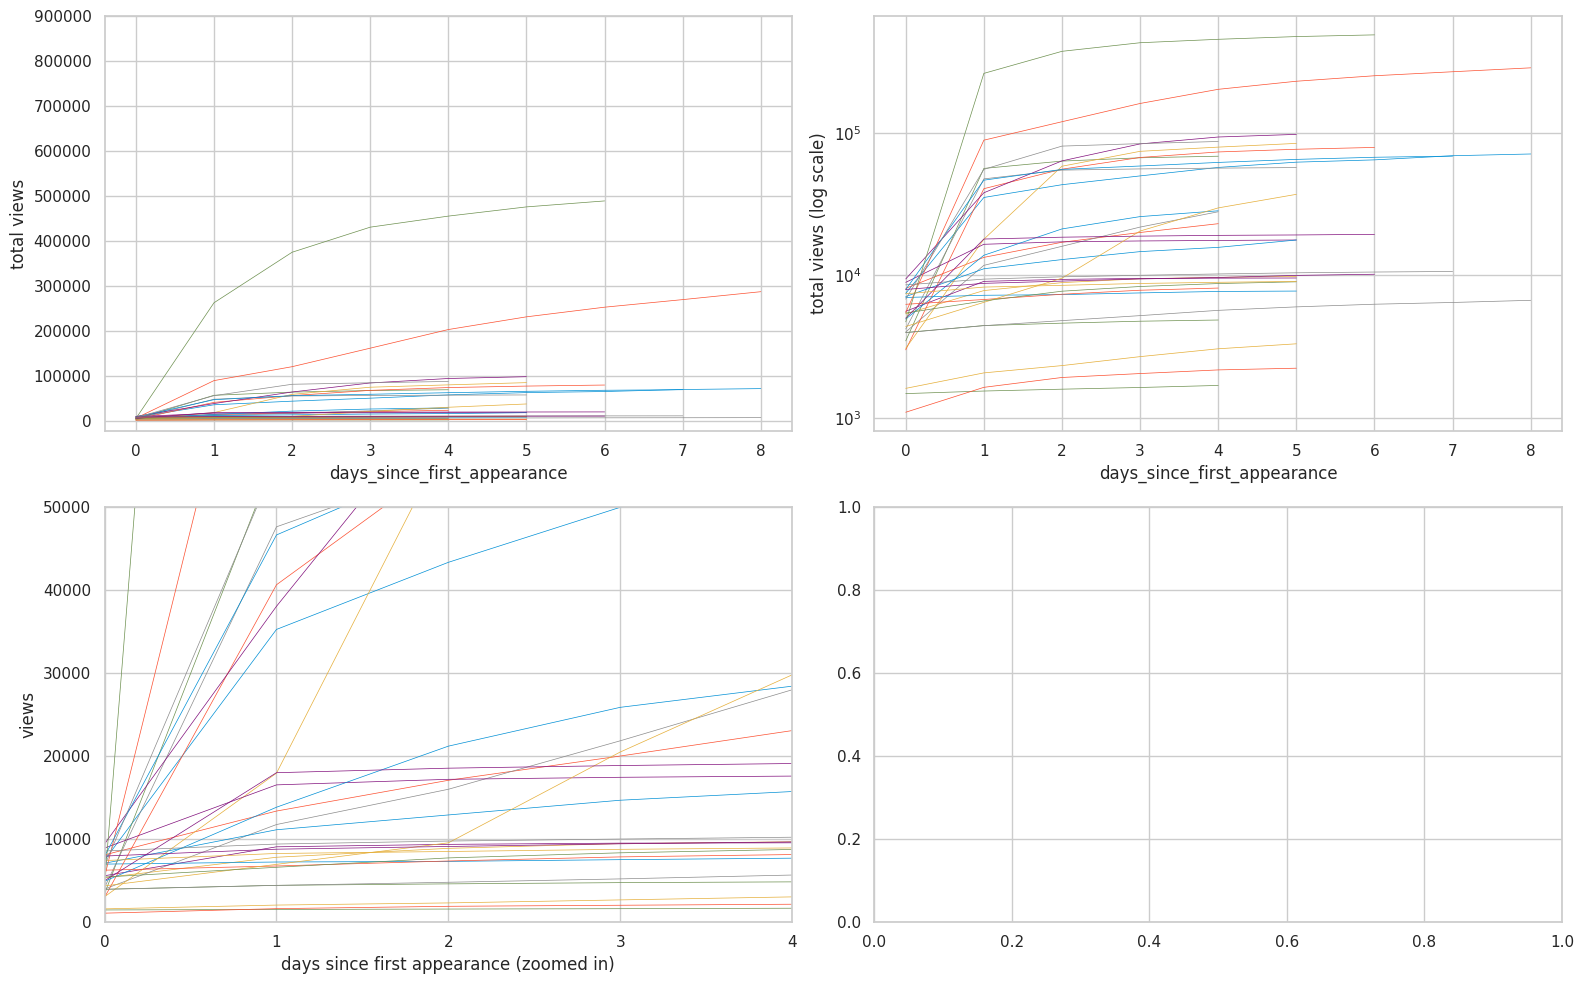

In [84]:
with sns.axes_style("whitegrid"), sns.plotting_context(rc={"lines.linewidth": 0.5}):
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2,2, figsize=(16, 10))

    for i in small_longevity_video_ids.sample(30)['video_id']:      # sample 30 random videos from our small video list
        video_i = small_longevity_videos.filter(pl.col('video_id') == i)
        sns.lineplot(video_i, x='days_since_first_appearance', y='views', ax=ax1)
        sns.lineplot(video_i, x='days_since_first_appearance', y='views', ax=ax2)
        sns.lineplot(video_i, x='days_since_first_appearance', y='views', ax=ax3)

    ax1.set_ylabel('total views')
    ax2.set_ylabel('total views (log scale)')

    ax1.set_yticks(range(0, 1000000, 100000))
    ax2.set_yscale('log')

    ax3.set_xticks(range(0, 5, 1))
    # ax3.set_yticks(range(0,150001, 15000))
    ax3.set_xlim(0,4)
    ax3.set_ylim(0,50000)
    ax3.set_xlabel('days since first appearance (zoomed in)')


plt.tight_layout()
plt.show

There is one other thing I want to try before we move on from the visualizations: What if we plot the daily view count instead of the cumulative sum? This means we miss out on one day of data (a fence post problem: we have n observation dates [the fence posts] but only n - 1 inter-day periods for which we can calculate the relative change, that is the additional views)

In [85]:
small_longevity_videos = small_longevity_videos.with_columns(
                                                daily_views = (pl.col('views') - pl.col('views').shift().over('video_id')) //    # diff in viewer count from day before
                                                             (pl.col('trending_date') - pl.col('trending_date').shift().over('video_id')).dt.total_days()) # offset for non-consecutive days
display(small_longevity_videos.select('video_id', 'title', 'trending_date', 'views', 'daily_views').head(10))

# let's add this column to the full df as well:
us = us.with_columns(daily_views = (pl.col('views') - pl.col('views').shift().over('video_id', order_by='trending_date')) //
                                    (pl.col('trending_date') - pl.col('trending_date').shift().over('video_id', order_by='trending_date')).dt.total_days()
                                    )    

video_id,title,trending_date,views,daily_views
str,str,date,i64,i64
"""-37nIo_tLnk""","""Christmas Day 2000""",2017-12-26,"2,863",null
"""-37nIo_tLnk""","""Christmas Day 2000""",2017-12-27,"2,987",124
"""-37nIo_tLnk""","""Christmas Day 2000""",2017-12-28,"3,052",65
"""-37nIo_tLnk""","""Christmas Day 2000""",2017-12-29,"3,085",33
"""-37nIo_tLnk""","""Christmas Day 2000""",2017-12-30,"3,111",26
"""-37nIo_tLnk""","""Christmas Day 2000""",2017-12-31,"3,130",19
"""-37nIo_tLnk""","""Christmas Day 2000""",2018-01-01,"3,148",18
"""-37nIo_tLnk""","""Christmas Day 2000""",2018-01-02,"3,170",22
"""-_jlqATo9eo""","""Padma Lakshmi On A #TopChef’s …",2018-02-15,"3,741",null


<function matplotlib.pyplot.show(close=None, block=None)>

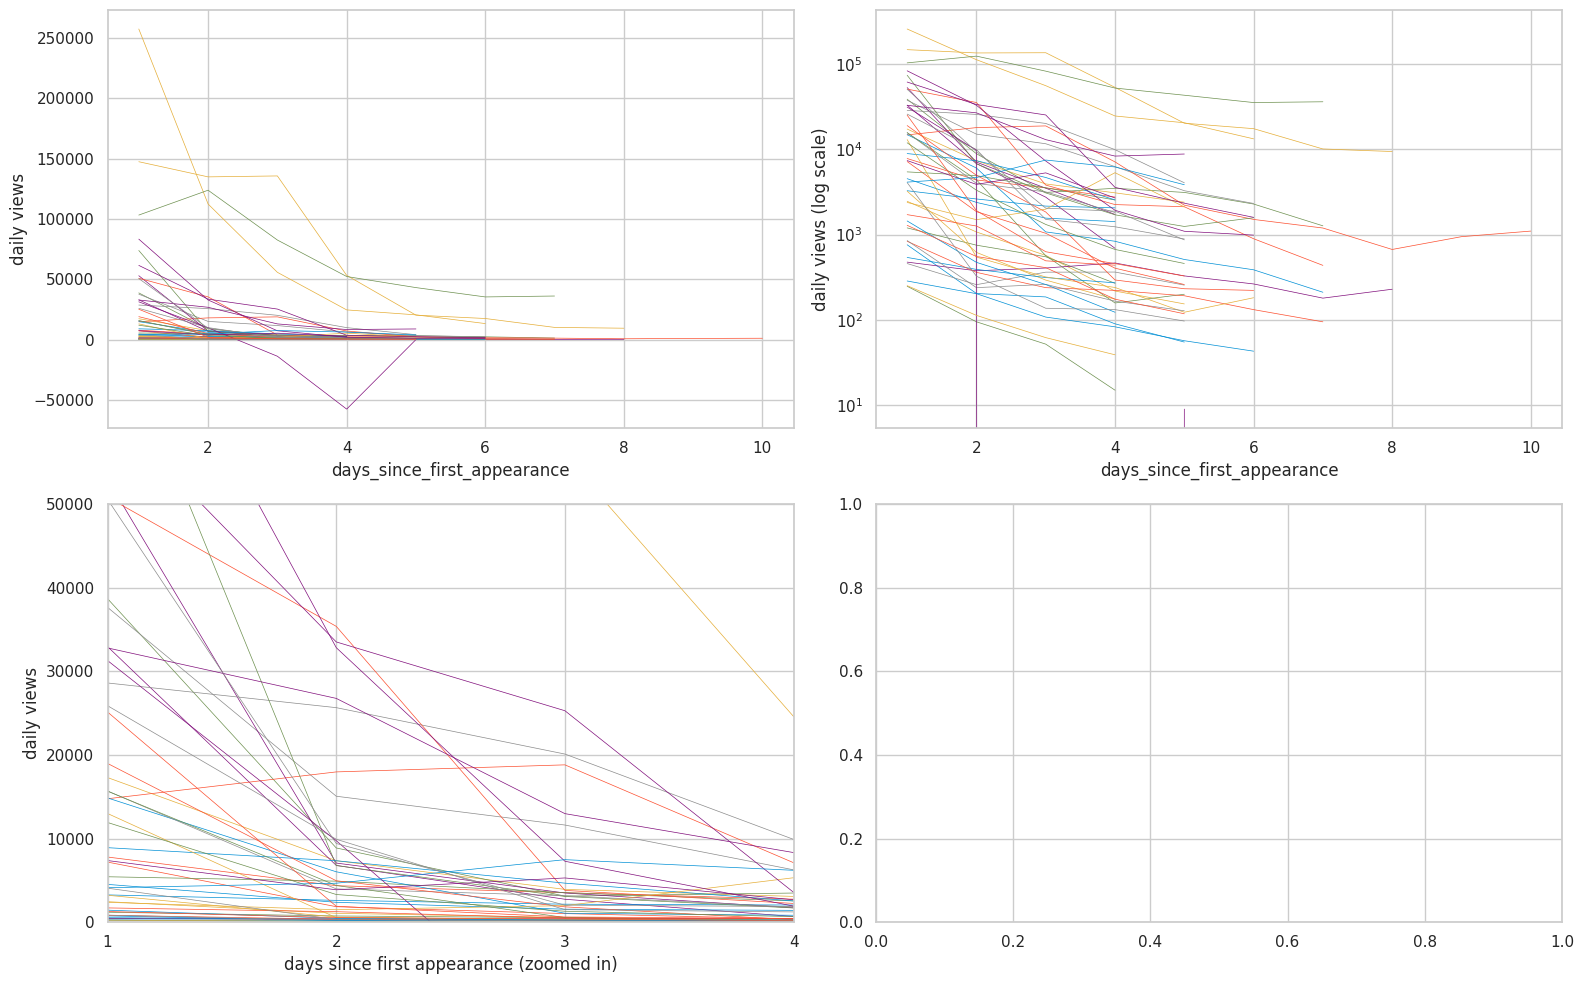

In [86]:
with sns.axes_style("whitegrid"), sns.plotting_context(rc={"lines.linewidth": 0.5}):
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2,2, figsize=(16, 10))

    for i in small_longevity_video_ids.sample(50)['video_id']:      # sample 30 random videos from our small video list
        video_i = small_longevity_videos.filter((pl.col('video_id') == i) & pl.col('daily_views').is_not_null())
        sns.lineplot(video_i, x='days_since_first_appearance', y='daily_views', ax=ax1)
        sns.lineplot(video_i, x='days_since_first_appearance', y='daily_views', ax=ax2)
        sns.lineplot(video_i, x='days_since_first_appearance', y='daily_views', ax=ax3)

    ax1.set_ylabel('daily views')
    ax2.set_ylabel('daily views (log scale)')

    # ax1.set_yticks(range(0, 500001, 50000))
    ax2.set_yscale('log')

    ax3.set_xticks(range(1, 5, 1))
    # ax3.set_yticks(range(0,150001, 15000))
    ax3.set_xlim(1,4)
    ax3.set_ylim(0,50000)
    ax3.set_ylabel('daily views')
    ax3.set_xlabel('days since first appearance (zoomed in)')


plt.tight_layout()
plt.show

In this view, one thing becomes very clear that you had to kinda look for more carefully in the total views: Predominantly, daily views trend down. This is no big surprise, generally speaking. Video trends are quick-lived, and hot videos experience a return to the mean. Still, I would have thought that in our diagrams here we have strongly selected for videos that could buck this trend: We have selected for small video, that are hot, and stay in the trends for a comparatively long time. It is easy to tell the story of a video by a small unknown creator slowly becoming viral, increasing in popularity every day until it rules the internet (for a short while). In contrast, what we see is that  videos get a big boost between days 1 and 2 on the list, and then taper off in almost all cases. 

It is unfortunate that we cannot really see what happened before that. If you look at our previous total view-diagrams, you can kinda get the story for the relationship between day 1 and day 2. And there you can see that there *are* a number of videos that start quite small on day one - below our cutoff of 10,000 total views - that then skyrocket on day 2 with a big multiple in their viewership counts. These videos tend to get more viewers afterwards, too, just not as many as between days 1 and 2. They taper off. So let's test this hypothesis: That there is a class of videos that gets a big boost after appearing on the list for the first time  (that is, its total view count at least doubles between day 1 and 2 on the list) and that most of these videos never again get as many views per day as between days 1 and 2:

Here we can see that almost all doublings happened for videos on their second day in the trending list:

In [87]:
display(us.filter(pl.col('daily_views') > pl.col('views') * 0.5).group_by('days_since_first_appearance').len().sort('days_since_first_appearance'))
print(f"Number of unique videos that had a doubling day: {us.filter(pl.col('daily_views') > pl.col('views') * 0.5).unique('video_id').height}")

days_since_first_appearance,len
i64,u32
1,883
2,27
3,10
4,4
5,3
6,2
10,1


Number of unique videos that had a doubling day: 895


Now how many of these videos could reach the same or higher daily viewer counts on subsequent days?

In [88]:
sustainers = us.filter(
    (
        (pl.col('daily_views') > pl.col('views') * 0.5) & # day with a doubling of views &
        (pl.col('daily_views') < pl.col('daily_views').max().over('video_id')) # that video has a (subsequent) day with even higher daily views
    ).any().over('video_id'))   # keep all rows for videos that match these conditions
print(f'Number of videos that had a doubling of views on a single day AND that had another day with a higher daily view count: {sustainers.unique("video_id").height}')

sustainers_groupby = sustainers.group_by('video_id').agg(pl.col('title').first(), 
                                    pl.col('daily_views').filter(pl.col('daily_views') > pl.col('views') * 0.5).sort().alias('views on doubling day'), 
                                    pl.col('daily_views').max().alias('max daily views'),
                                    pl.col('views').max().alias('max total views'),
                                    pl.col('no_appearances').first()
                                    ).sort('max total views', descending=True)
sustainers_groupby

Number of videos that had a doubling of views on a single day AND that had another day with a higher daily view count: 97


video_id,title,views on doubling day,max daily views,max total views,no_appearances
str,str,list[i64],i64,i64,u32
"""aJOTlE1K90k""","""Maroon 5 - Girls Like You ft. …","[5,655,150]","8,866,197","66,529,577",10
"""9TUBf6l7FBg""","""Coachella 2018 LIVE Channel 1""","[7,538,851, 12,867,708]","12,867,708","24,004,779",3
"""yvicqMrAHvQ""","""Turkish Airlines - 5 Senses wi…","[3,693,729]","3,917,406","23,932,421",7
"""8JnfIa84TnU""","""Clean Bandit - Solo feat. Demi…","[1,143,109]","3,035,832","21,250,349",14
"""kton-qrKNLc""","""Meghan Trainor - No Excuses""","[1,581,143]","1,909,353","19,998,243",15
"""eACohWVwTOc""","""The Chainsmokers - Sick Boy""","[1,942,669]","2,318,531","16,219,716",8
"""8MPbR6Cbwi4""","""Justin Timberlake - Say Someth…","[2,522,691]","2,584,499","15,043,210",7
"""SA7AIQw-7Ms""","""G-Eazy & Halsey - Him & I (Off…","[2,299,556]","2,412,799","14,860,998",7
"""V69XYIRjKww""","""Tom Clancy’s Jack Ryan – Super…","[1,823,460]","3,041,081","12,030,454",5


ALright, we're down to 97 truly viral videos that (a) doubled their views on a single day and (b) managed to keep that growth rate (or, in a select few cases, even double *again* on subsequent days). These videos cover a big size range too, from the Best Carol Burnett Show Blooper video with a max daily views of 11,491 to the Coachella Livestream with over 12 million daily views at the maximum. 

Just for fun, I looked at that Carol Burnett Show Bloopers video on youtube - it's still up, and in the years since the video has garnered a total of 12.7 million views! That's a total growth of around 55,200%! Interesting.

Anyway, I want to get more details about these growth trajectories within the dataset.

In [89]:
views = us.group_by("trending_date").len()
views["len"].value_counts().sort('len')

len,count
u32,u32
149,1
196,3
197,2
198,5
199,22
200,172
